# ITELv5 - SECCIÓN 6: ENTRENAMIENTO Y EVALUACIÓN (MLP y LogReg)

En esta sección cargaremos embeddings cacheados (Sección 5), prepararemos los datasets, y entrenaremos y evaluaremos los dos modelos seleccionados:
1.  **MLP (Deep Learning)**
2.  **Regresión Logística (Machine Learning Clásico)**

In [ ]:
import os
from pathlib import Path

# Asegurar que el CWD sea la carpeta de notebooks
# (IntelliJ puede configurar un CWD distinto al de Jupyter Lab)
_anchor = Path('ITELv5_01_CONFIGURACION.ipynb')
if not _anchor.exists():
    for _candidate in Path.cwd().rglob('ITELv5_01_CONFIGURACION.ipynb'):
        os.chdir(_candidate.parent)
        break
print(f'📂 CWD: {Path(".").resolve()}')


In [1]:
# ===============================================================_
# ITELv5 - SECCIÓN 6: ENTRENAMIENTO Y EVALUACIÓN (MLP y LogReg)
# ===============================================================_

# 6.1 - Importar librerías y configurar entorno
%run "./ITELv5_01_CONFIGURACION.ipynb"

import torch, numpy as np, pandas as pd
import torch.nn as nn
from pathlib import Path
import json, random, re
import joblib 
from typing import Optional

# Sklearn - Métricas y Reportes
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, recall_score, precision_score, f1_score, roc_auc_score
# Sklearn - Preprocessing
from sklearn.preprocessing import StandardScaler
# Sklearn - Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
# Sklearn - Selección de Modelos y HPO
from sklearn.model_selection import StratifiedKFold, ParameterGrid, GridSearchCV
try:
    from sklearn.model_selection import StratifiedGroupKFold
except Exception:
    print("Advertencia: StratifiedGroupKFold no disponible. Usando StratifiedKFold.")
    StratifiedGroupKFold = StratifiedKFold # Fallback
# Modelos de Boosting
from xgboost import XGBClassifier

print('✅ Entorno listo (Sección 6)')

🔍 Verificando estructura de carpetas...

✅ Estructura de carpetas completa.
🔧 Dependencias comprobadas.

📁 BASE_DIR: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL
🖥️ GPU disponible: False
Rutas Principales de ITELv5:
Datos_Brutos:     C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Datos_Brutos
Datos Procesados: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Datos_Procesados
Modelos:          C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Modelos
Reportes (CSV):   C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\CSV
Reportes (Figuras): C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\Figuras
Logs:             C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Logs
🔍 Carpeta Healthy con 308 subrutas de vocales
🔍 Carpeta Patients con 378 subrutas de vocales
✅ Configuración ITELv5 lista.
✅ Entorno listo (Sección 6)


In [2]:
# 6.2 - Cargar embeddings cacheados (Sección 5)

# Actualizado para usar la nueva carpeta PROCESADOS_DIR
emb_dir = ITELConfig.PROCESADOS_DIR 
npy_file = emb_dir / 'embeddings_v5.npy'
info_file = emb_dir / 'embeddings_info_v5.csv'

if not npy_file.exists() or not info_file.exists():
    raise FileNotFoundError(f'No se encontraron embeddings cacheados en {emb_dir}. Ejecuta la Sección 5.')

X = np.load(npy_file)
info = pd.read_csv(info_file)

print('✅ Embeddings y metadata cargados')
print(' - Shape X:', X.shape)
print(' - Registros info:', len(info))

✅ Embeddings y metadata cargados
 - Shape X: (3730, 4608)
 - Registros info: 3730


In [3]:
# 6.3 - Preparar Labels y Grupos (Sujetos)

# 1. Mapear Labels
label_map = {'Healthy': 0, 'Patients': 1}
y = info['categoria'].map(label_map).values

# 2. Derivar ID de Sujeto (Grupo) para el GroupKFold
if 'sujeto' not in info.columns:
    def derive_subject(name: str) -> str:
        if not isinstance(name, str): return 'UNK'
        m = re.match(r'^(H\d+|P\d+)', name)
        if m: return m.group(1)
        return name.split('_')[0]
    info['sujeto'] = info.get('nombre', pd.Series(['UNK']*len(info))).apply(derive_subject)

groups = info['sujeto']
print(f"Datos listos: {len(X)} muestras, {len(y)} etiquetas.")
print(f"Grupos definidos: {groups.nunique()} sujetos únicos.")

Datos listos: 3730 muestras, 3730 etiquetas.
Grupos definidos: 3726 sujetos únicos.


In [ ]:
# ===============================================================_
# 6.3.5 — Split 80% / 10% / 10%
# ===============================================================_
#
#   80% → 5 modelos vía k-fold CV  (este notebook)
#   10% → modelo final de producción (Notebook 08)
#   10% → prueba manual              (Notebook 07 + holdout_manual_v5.csv)
#
# GroupShuffleSplit garantiza que ningún sujeto aparece en dos particiones.

from sklearn.model_selection import GroupShuffleSplit

# ── Paso 1: separar el 10% de prueba manual ──────────────────
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=ITELConfig.SEED)
idx_90, idx_manual = next(gss1.split(X, y, groups=groups))

X_90      = X[idx_90]
y_90      = y[idx_90]
groups_90 = groups.iloc[idx_90].reset_index(drop=True)
info_90   = info.iloc[idx_90].reset_index(drop=True)

X_manual     = X[idx_manual]
y_manual     = y[idx_manual]
info_manual  = info.iloc[idx_manual].reset_index(drop=True)

# ── Paso 2: del 90% restante, separar 10% para el modelo final
# (≈ 11.1% del 90% ≈ 10% del total)
gss2 = GroupShuffleSplit(n_splits=1, test_size=1/9, random_state=ITELConfig.SEED)
idx_cv_rel, idx_final_rel = next(gss2.split(X_90, y_90, groups=groups_90))

# Índices absolutos (en el array original X)
idx_cv    = idx_90[idx_cv_rel]    # ~80% del total → entra al CV
idx_final = idx_90[idx_final_rel] # ~10% del total → modelo final

# Datos para el CV (80%)
X_train_cv = X[idx_cv]
y_train_cv = y[idx_cv]
groups_cv  = groups.iloc[idx_cv].reset_index(drop=True)
info_cv    = info.iloc[idx_cv].reset_index(drop=True)

# Datos para el modelo final (10%)
X_final    = X[idx_final]
y_final    = y[idx_final]
info_final = info.iloc[idx_final].reset_index(drop=True)

# ── Paso 3: guardar índices y CSVs ───────────────────────────
# Índices para notebook 08
np.save(ITELConfig.PROCESADOS_DIR / 'idx_final_v5.npy',  idx_final)
np.save(ITELConfig.PROCESADOS_DIR / 'idx_manual_v5.npy', idx_manual)

# CSV de holdout manual (con rutas WAV para Notebook 07)
info_manual_export = info_manual.copy()
info_manual_export['y_true']       = y_manual
info_manual_export['label_nombre'] = info_manual_export['y_true'].map({0:'Healthy', 1:'Patients'})
holdout_csv = ITELConfig.CSV_DIR / 'holdout_manual_v5.csv'
info_manual_export.to_csv(holdout_csv, index=False)

# ── Resumen ───────────────────────────────────────────────────
print('═' * 55)
print('  SPLIT 80 / 10 / 10')
print('═' * 55)
print(f'  CV  (5 modelos) : {len(X_train_cv):>5} audios  (~80%)')
print(f'  Modelo final    : {len(X_final):>5} audios  (~10%)')
print(f'  Prueba manual   : {len(X_manual):>5} audios  (~10%)')
print(f'    └─ Healthy  : {(y_manual==0).sum()}')
print(f'    └─ Patients : {(y_manual==1).sum()}')
print(f'\n  📄 {holdout_csv}')
print('═' * 55)

# A partir de aquí X, y, groups e info = 80% para el CV
X      = X_train_cv
y      = y_train_cv
groups = groups_cv
info   = info_cv
print('\n✅ X/y/groups/info actualizados al 80% de CV.')


In [4]:
# 6.4 - Definir Helpers de Validación Cruzada (CV)

N_SPLITS = 5
SEED = ITELConfig.SEED

# Helper para obtener splits (prioriza CV por Sujeto)
def get_cv(y, groups: Optional[pd.Series], n_splits=N_SPLITS, seed=SEED):
    if groups is not None and groups.nunique() > n_splits:
        print(f"Usando StratifiedGroupKFold con {n_splits} splits.")
        sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        return list(sgkf.split(X, y, groups=groups))
    else:
        print(f"Usando StratifiedKFold estándar con {n_splits} splits.")
        skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        return list(skf.split(X, y))

# Helper para evaluar pipelines de Sklearn
def eval_cv_manual(pipe, splits):
    scores = []
    for tr, va in splits:
        est = clone(pipe)
        est.fit(X[tr], y[tr])
        y_pred = est.predict(X[va])
        scores.append(accuracy_score(y[va], y_pred))
    return float(np.mean(scores))

# Generar los splits UNA VEZ para que todos los modelos usen los mismos
splits_grp = get_cv(y, groups, n_splits=N_SPLITS, seed=SEED)

Usando StratifiedGroupKFold con 5 splits.


In [5]:
# 6.5 - Preparar Archivos de Resultados Finales (Rutas actualizadas)

dest_csv = ITELConfig.CSV_DIR
dest_modelos = ITELConfig.MODELS_DIR

# Archivos de Reportes (CSV)
resumen_csv = dest_csv / 'resultados_modelos_v5.csv'
hpo_csv = dest_csv / 'hpo_resultados_v5.csv'

# ---- AÑADIR/MODIFICAR ESTAS LÍNEAS ----
preds_mlp_csv_path = dest_csv / 'predicciones_test_mlp_v5.csv' # Renombrado para claridad
preds_lr_csv_path = dest_csv / 'predicciones_test_logreg_v5.csv' # NUEVO ARCHIVO
# ------------------------------------

# Limpiar archivos de resultados si existen
if resumen_csv.exists():
    resumen_csv.unlink()
if hpo_csv.exists():
    hpo_csv.unlink()
if preds_mlp_csv_path.exists():
    preds_mlp_csv_path.unlink()
if preds_lr_csv_path.exists(): # NUEVA LÍNEA
    preds_lr_csv_path.unlink() # NUEVA LÍNEA

print(f"💾 Archivo de resumen de resultados listo en: {resumen_csv}")

💾 Archivo de resumen de resultados listo en: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\CSV\resultados_modelos_v5.csv


In [6]:
# ===============================================================_
# MODELO 1: REGRESIÓN LOGÍSTICA (LÍNEA BASE)
# ===============================================================_

# 6.6 - LogReg: HPO (GridSearch) y Evaluación con CV (MODIFICADO)
print("🚀 Entrenando Modelo 1: Regresión Logística (con HPO y CV)")

# 1. Definir el pipeline
pipe_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=SEED)
)

# 2. Definir el Grid de Parámetros
param_grid_lr = {
    'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'logisticregression__solver': ['liblinear', 'saga']
}

# --- INICIO DE CAMBIOS ---

# 2.5 - Definir las métricas que queremos reportar
scoring_metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# 3. Configurar GridSearchCV (Optimizado para F1-Score)
gs_lr = GridSearchCV(
    estimator=pipe_lr,
    param_grid=param_grid_lr,
    cv=splits_grp,
    scoring=scoring_metrics,    # <-- Calcula TODAS estas métricas
    refit='f1',                 # <-- Elige 'f1' como la métrica principal para optimizar
    n_jobs=-1,
    verbose=1,
    return_train_score=False    # Para no saturar la salida
)

# 4. Ejecutar el HPO
print("Iniciando GridSearchCV para LogReg (optimizando para F1-Score)...")
gs_lr.fit(X, y) # Usamos X e y completos

# 5. Obtener resultados del mejor modelo (basado en F1)
best_index = gs_lr.best_index_
best_params_lr = gs_lr.best_params_

# Extraer todas las métricas del mejor estimador
f1_lr = gs_lr.best_score_ # Esta es la métrica de 'refit' (f1)
acc_lr = gs_lr.cv_results_['mean_test_accuracy'][best_index]
recall_lr = gs_lr.cv_results_['mean_test_recall'][best_index]
precision_lr = gs_lr.cv_results_['mean_test_precision'][best_index]
roc_auc_lr = gs_lr.cv_results_['mean_test_roc_auc'][best_index]

print(f"\n🎯 [LogReg sklearn] Mejores Params (optimizados para 'f1'): {best_params_lr}")
print(f"🎯 [LogReg sklearn] CV F1-Score: {f1_lr:.4f} (Métrica de 'refit')")
print(f"🎯 [LogReg sklearn] CV Accuracy: {acc_lr:.4f}")
print(f"🎯 [LogReg sklearn] CV Recall: {recall_lr:.4f}")
print(f"🎯 [LogReg sklearn] CV Precision: {precision_lr:.4f}")
print(f"🎯 [LogReg sklearn] CV ROC-AUC: {roc_auc_lr:.4f}")


# 6. Guardar en el resumen de resultados (ruta actualizada)
df_res_lr = pd.DataFrame([{ 
    'modelo': 'LogReg_sklearn_CV_HPO_f1', 
    'test_accuracy': acc_lr,
    'test_f1': f1_lr,
    'test_recall': recall_lr,
    'test_precision': precision_lr,
    'test_roc_auc': roc_auc_lr
}])
df_res_lr.to_csv(resumen_csv, mode='a', header=not resumen_csv.exists(), index=False)
print(f"💾 Resultados LogReg (HPO) añadidos a {resumen_csv}")

# --- FIN DE CAMBIOS ---

# 7. Guardar el mejor pipeline (.joblib) Y el scaler (.npz) para Notebook 08
print("💾 Guardando el mejor estimador (LogReg + Scaler) de HPO...")
best_logreg_pipeline = gs_lr.best_estimator_

# Extraer el scaler y sus atributos
scaler_logreg = best_logreg_pipeline.named_steps['standardscaler']
scaler_mean = scaler_logreg.mean_
scaler_scale = scaler_logreg.scale_

# Guardar el pipeline .joblib
save_path_joblib = ITELConfig.MODELS_DIR / 'logreg_hpo_v5.joblib'
joblib.dump(best_logreg_pipeline, save_path_joblib)

# Guardar el scaler .npz (para el notebook 08)
save_path_scaler = ITELConfig.MODELS_DIR / 'linear_head_scaler.npz'
np.savez(save_path_scaler, mean=scaler_mean, scale=scaler_scale)

print(f"✅ Mejor pipeline LogReg guardado en: {save_path_joblib}")
print(f"✅ Scaler de LogReg guardado en: {save_path_scaler}")

🚀 Entrenando Modelo 1: Regresión Logística (con HPO y CV)
Iniciando GridSearchCV para LogReg (optimizando para F1-Score)...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

🎯 [LogReg sklearn] Mejores Params (optimizados para 'f1'): {'logisticregression__C': 0.01, 'logisticregression__solver': 'saga'}
🎯 [LogReg sklearn] CV F1-Score: 0.9266 (Métrica de 'refit')
🎯 [LogReg sklearn] CV Accuracy: 0.9196
🎯 [LogReg sklearn] CV Recall: 0.9244
🎯 [LogReg sklearn] CV Precision: 0.9289
🎯 [LogReg sklearn] CV ROC-AUC: 0.9745
💾 Resultados LogReg (HPO) añadidos a C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\CSV\resultados_modelos_v5.csv
💾 Guardando el mejor estimador (LogReg + Scaler) de HPO...
✅ Mejor pipeline LogReg guardado en: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Modelos\logreg_hpo_v5.joblib
✅ Scaler de LogReg guardado en: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Modelos\linear_head_scaler.npz


In [7]:
# 6.7 - LogReg: Generar Predicciones de CV (para Comparación en 07)
print("🚀 Generando predicciones de 5-folds (LogReg)...")

# Cargar los mejores parámetros encontrados en la celda 6.6
if 'best_params_lr' not in locals():
    print("Error: 'best_params_lr' no encontrado. Ejecuta la celda 6.6 (HPO) primero.")
else:
    print(f"Usando HParams de LogReg: {best_params_lr}")
    
    # 1. Definir el pipeline con los MEJORES parámetros
    pipe_lr_best = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000, 
            random_state=SEED, 
            C=best_params_lr['logisticregression__C'], 
            solver=best_params_lr['logisticregression__solver']
        )
    )

    # 2. Listas para recopilar predicciones
    all_info_test_dfs_lr = []
    all_y_true_lr = []
    all_y_pred_lr = []
    all_y_proba_lr = []

    # 3. Ejecutar el bucle de 5-folds (usando los mismos 'splits_grp' de la celda 6.4)
    for fold, (tr_idx, va_idx) in enumerate(splits_grp):
        #print(f"--- LogReg Fold {fold+1}/{N_SPLITS} ---")
        
        X_tr, y_tr = X[tr_idx], y[tr_idx]
        X_va, y_va = X[va_idx], y[va_idx]
        info_va = info.iloc[va_idx] 
        
        model_lr_fold = clone(pipe_lr_best)
        model_lr_fold.fit(X_tr, y_tr)
        
        # Predecir
        y_pred_fold_lr = model_lr_fold.predict(X_va)
        y_proba_fold_lr = model_lr_fold.predict_proba(X_va)[:, 1] # Proba de 'Patients'
        
        # Guardar resultados del fold
        all_y_true_lr.append(y_va)
        all_y_pred_lr.append(y_pred_fold_lr)
        all_y_proba_lr.append(y_proba_fold_lr)
        all_info_test_dfs_lr.append(info_va)

    # 4. Concatenar y guardar PREDICCIONES INDIVIDUALES
    df_pred_test_lr_full = pd.concat(all_info_test_dfs_lr)
    df_pred_test_lr_full['y_true'] = np.concatenate(all_y_true_lr)
    df_pred_test_lr_full['y_pred_logreg'] = np.concatenate(all_y_pred_lr)
    df_pred_test_lr_full['proba_patient_logreg'] = np.concatenate(all_y_proba_lr)

    # (preds_lr_csv_path definido en celda 6.5)
    df_pred_test_lr_full.to_csv(preds_lr_csv_path, index=False)
    print(f"💾 Predicciones de Test (5-Folds) del LogReg guardadas en: {preds_lr_csv_path}")

🚀 Generando predicciones de 5-folds (LogReg)...
Usando HParams de LogReg: {'logisticregression__C': 0.01, 'logisticregression__solver': 'saga'}
💾 Predicciones de Test (5-Folds) del LogReg guardadas en: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\CSV\predicciones_test_logreg_v5.csv


In [8]:
# ===============================================================_
# MODELO 2: MLP (DEEP LEARNING)
# ===============================================================_

In [9]:
# 6.8 - Definir MLP
class MLP(nn.Module):
    def __init__(self, in_dim=4608, hidden=512, dropout=0.3, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden//2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden//2, num_classes)
        )
    def forward(self, x):
        return self.net(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Definición MLP lista. Usando device: {device}")

✅ Definición MLP lista. Usando device: cpu


In [10]:
# 6.9 - MLP: Grid de hiperparámetros rápido (MODIFICADO)
print("🚀 Iniciando HPO (rápido) para MLP")

# Usar el primer fold de la CV como set de train/val para el HPO
tr_idx_hpo, va_idx_hpo = splits_grp[0] 
X_train_hpo, y_train_hpo = X[tr_idx_hpo], y[tr_idx_hpo]
X_val_hpo, y_val_hpo = X[va_idx_hpo], y[va_idx_hpo]

# Escalar
scaler_hpo = StandardScaler()
X_train_hpo_s = scaler_hpo.fit_transform(X_train_hpo)
X_val_hpo_s = scaler_hpo.transform(X_val_hpo)

# Tensores para HPO
X_train_t = torch.tensor(X_train_hpo_s, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train_hpo, dtype=torch.long).to(device)
X_val_t = torch.tensor(X_val_hpo_s, dtype=torch.float32).to(device)
y_val_t = torch.tensor(y_val_hpo, dtype=torch.long).to(device)

param_grid = {
    'hidden': [256, 512],
    'dropout': [0.2, 0.3, 0.5],
    'lr': [1e-3, 5e-4],
    'weight_decay': [1e-5, 1e-4],
    'epochs': [100],
}

def train_eval_once(hidden, dropout, lr, weight_decay, epochs=100):
    m = MLP(in_dim=X.shape[1], hidden=hidden, dropout=dropout).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=lr, weight_decay=weight_decay)
    crit = nn.CrossEntropyLoss()
    best = 0.0
    for _ in range(epochs):
        m.train(); opt.zero_grad()
        loss = crit(m(X_train_t), y_train_t)
        loss.backward(); opt.step()
        m.eval()
        with torch.inference_mode():
            val_acc = (m(X_val_t).argmax(dim=1) == y_val_t).float().mean().item()
        if val_acc > best: best = val_acc
    return best

results = []
best_params, best_score = None, -1.0
for p in ParameterGrid(param_grid):
    score = train_eval_once(**p)
    results.append({**p, 'val_acc': score})
    if score > best_score:
        best_score, best_params = score, p

print(f"Mejores hiperparámetros (rápido): {best_params} | val_acc= {best_score:.4f}")

# --- Guardar los resultados del HPO ---
df_hpo_results = pd.DataFrame(results).sort_values('val_acc', ascending=False)
df_hpo_results.to_csv(hpo_csv, index=False)
print(f"💾 Resultados HPO guardados en {hpo_csv}")

# --- Guardar los mejores HParams en JSON para notebook 08 ---
hparams_path = ITELConfig.MODELS_DIR / 'mlp_hparams_v5.json'
with open(hparams_path, 'w') as f:
    json.dump(best_params, f, indent=2)
print(f"💾 Mejores HParams (MLP) guardados en {hparams_path}")

🚀 Iniciando HPO (rápido) para MLP
Mejores hiperparámetros (rápido): {'dropout': 0.5, 'epochs': 100, 'hidden': 256, 'lr': 0.001, 'weight_decay': 1e-05} | val_acc= 0.9434
💾 Resultados HPO guardados en C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\CSV\hpo_resultados_v5.csv
💾 Mejores HParams (MLP) guardados en C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Modelos\mlp_hparams_v5.json


In [11]:
# 6.10 - MLP: Entrenamiento y Evaluación con CV por Sujeto (MODIFICADO)

print("🚀 Entrenando Modelo 2: MLP (con CV por Sujeto)")

if 'best_params' not in locals() or best_params is None:
    print("Advertencia: 'best_params' no encontrado. Usando defaults.")
    best_params_mlp = {'hidden': 256, 'dropout': 0.5, 'lr': 0.001, 'weight_decay': 1e-05}
else:
    best_params_mlp = best_params

# Usar las epochs del HPO o las que tenías
EPOCHS = best_params_mlp.get('epochs', 100) 

# (Se mantienen las listas 'all_scores_mlp' y 'all_cms_mlp' aunque ya no usaremos all_scores_mlp)
all_scores_mlp = []
all_cms_mlp = np.zeros((2, 2), dtype=int)

# Listas para recopilar predicciones
all_info_test_dfs = []
all_y_true = []
all_y_pred_mlp = []
all_y_proba_mlp = []

# (splits_grp debe estar definido en la celda 6.4)
for fold, (tr_idx, va_idx) in enumerate(splits_grp):
    print(f"--- MLP Fold {fold+1}/{N_SPLITS} ---")
    
    X_tr, y_tr = X[tr_idx], y[tr_idx]
    X_va, y_va = X[va_idx], y[va_idx]
    info_va = info.iloc[va_idx] 
    
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_va_s = scaler.transform(X_va)

    X_train_t = torch.tensor(X_tr_s, dtype=torch.float32).to(device)
    y_train_t = torch.tensor(y_tr, dtype=torch.long).to(device)
    X_val_t = torch.tensor(X_va_s, dtype=torch.float32).to(device)
    y_val_t = torch.tensor(y_va, dtype=torch.long).to(device)

    model = MLP(
        in_dim=X.shape[1], 
        hidden=best_params_mlp['hidden'], 
        dropout=best_params_mlp['dropout']
    ).to(device)
    
    optimizer = torch.optim.Adam(
        model.parameters(), 
        lr=best_params_mlp['lr'], 
        weight_decay=best_params_mlp['weight_decay']
    )
    criterion = nn.CrossEntropyLoss()

    best_val_acc_fold, best_state_fold = 0.0, None
    
    for epoch in range(1, EPOCHS + 1):
        model.train(); optimizer.zero_grad()
        loss = criterion(model(X_train_t), y_train_t)
        loss.backward(); optimizer.step()

        model.eval()
        with torch.inference_mode():
            val_acc = (model(X_val_t).argmax(dim=1) == y_val_t).float().mean().item()
        
        if val_acc > best_val_acc_fold:
            best_val_acc_fold = val_acc
            best_state_fold = model.state_dict()
    
    if best_state_fold is not None:
        model.load_state_dict(best_state_fold)
    
    # Guardar el modelo .pt de este fold (para notebook 08)
    fold_model_path = ITELConfig.MODELS_DIR / f'itelv5_mlp_fold_{fold+1}.pt'
    if best_state_fold:
        torch.save(best_state_fold, fold_model_path)
        print(f"💾 Modelo Fold {fold+1} guardado en {fold_model_path}")
    else:
        print(f"⚠️ No se guardó el modelo para el Fold {fold+1} (best_state_fold is None)")

    model.eval()
    with torch.inference_mode():
        logits_test = model(X_val_t)
        y_pred = logits_test.argmax(dim=1).cpu().numpy()
        y_proba = torch.softmax(logits_test, dim=1).cpu().numpy()[:, 1] # Probabilidad de 'Patients'
        y_true = y_val_t.cpu().numpy()
    
    # (Ya no necesitamos 'all_scores_mlp', pero mantenemos la CM)
    all_cms_mlp += confusion_matrix(y_true, y_pred)
    
    # Guardar resultados del fold
    all_y_true.append(y_true)
    all_y_pred_mlp.append(y_pred)
    all_y_proba_mlp.append(y_proba)
    all_info_test_dfs.append(info_va)

# --- Fin del Bucle de Folds ---

# 1. Concatenar todos los resultados de los folds
y_true_full = np.concatenate(all_y_true)
y_pred_full = np.concatenate(all_y_pred_mlp)
y_proba_full = np.concatenate(all_y_proba_mlp)

# 2. Calcular métricas agregadas (requiere sklearn.metrics importadas en celda 6.1)
acc_mlp_agg = accuracy_score(y_true_full, y_pred_full)
f1_mlp_agg = f1_score(y_true_full, y_pred_full)
recall_mlp_agg = recall_score(y_true_full, y_pred_full)
precision_mlp_agg = precision_score(y_true_full, y_pred_full)
roc_auc_mlp_agg = roc_auc_score(y_true_full, y_proba_full) # Usar y_proba para ROC-AUC

# 3. Imprimir métricas agregadas
print(f"\n🎯 [MLP] CV (Agregado) Accuracy: {acc_mlp_agg:.4f}")
print(f"🎯 [MLP] CV (Agregado) F1-Score: {f1_mlp_agg:.4f}")
print(f"🎯 [MLP] CV (Agregado) Recall: {recall_mlp_agg:.4f}")
print(f"🎯 [MLP] CV (Agregado) Precision: {precision_mlp_agg:.4f}")
print(f"🎯 [MLP] CV (Agregado) ROC-AUC: {roc_auc_mlp_agg:.4f}")

print("Matriz de confusión (Agregada de 5 Folds):\n", all_cms_mlp)

# 4. Guardar en el resumen de resultados (con todas las métricas)
df_res_mlp_cv = pd.DataFrame([{ 
    'modelo': 'MLP_HuBERT_v5_CV_Subject', 
    'test_accuracy': acc_mlp_agg,
    'test_f1': f1_mlp_agg,
    'test_recall': recall_mlp_agg,
    'test_precision': precision_mlp_agg,
    'test_roc_auc': roc_auc_mlp_agg
}])
df_res_mlp_cv.to_csv(resumen_csv, mode='a', header=not resumen_csv.exists(), index=False)
print(f"💾 Resultados MLP (CV) añadidos a {resumen_csv}")

# 5. Concatenar y guardar PREDICCIONES INDIVIDUALES (Ruta actualizada)
df_pred_test_mlp_full = pd.concat(all_info_test_dfs)
df_pred_test_mlp_full['y_true'] = y_true_full
df_pred_test_mlp_full['y_pred'] = y_pred_full
df_pred_test_mlp_full['proba_patient'] = y_proba_full

# (preds_mlp_csv_path definido en celda 6.5)
df_pred_test_mlp_full.to_csv(preds_mlp_csv_path, index=False)
print(f"💾 Predicciones de Test (5-Folds) del MLP guardadas en: {preds_mlp_csv_path}")

🚀 Entrenando Modelo 2: MLP (con CV por Sujeto)
--- MLP Fold 1/5 ---
💾 Modelo Fold 1 guardado en C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Modelos\itelv5_mlp_fold_1.pt
--- MLP Fold 2/5 ---
💾 Modelo Fold 2 guardado en C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Modelos\itelv5_mlp_fold_2.pt
--- MLP Fold 3/5 ---
💾 Modelo Fold 3 guardado en C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Modelos\itelv5_mlp_fold_3.pt
--- MLP Fold 4/5 ---
💾 Modelo Fold 4 guardado en C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Modelos\itelv5_mlp_fold_4.pt
--- MLP Fold 5/5 ---
💾 Modelo Fold 5 guardado en C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Modelos\itelv5_mlp_fold_5.pt

🎯 [MLP] CV (Agregado) Accuracy: 0.9303
🎯 [MLP] CV (Agregado) F1-Score: 0.9367
🎯 [MLP] CV (Agregado) Recall: 0.9380
🎯 [MLP] CV (Agregado) Precision: 0.9353
🎯 [MLP] CV (Agregado) ROC-AUC: 0.9801
Matriz de confusión (Agregada de 5 Folds):
 [[1547  133]
 [ 127 1923]]
💾 Resultados MLP (CV) añadidos a C:\Us

In [ ]:
# 6.11 - Comparar Resultados Finales
print("--- Comparación Final de Modelos (del HPO) ---")

if resumen_csv.exists():
    df_final_results = pd.read_csv(resumen_csv).sort_values('test_f1', ascending=False)
    # to_markdown requiere 'tabulate'; usamos to_string como alternativa
    try:
        import tabulate as _tab  # noqa: F401
        print(df_final_results.to_markdown(index=False))
    except ImportError:
        pd.set_option('display.max_columns', None)
        pd.set_option('display.width', 120)
        pd.set_option('display.float_format', '{:.4f}'.format)
        print(df_final_results.to_string(index=False))
else:
    print("No se encontró el archivo de resumen. Ejecuta las celdas de entrenamiento.")


🚀 Generando gráficos ROC comparativos (MLP vs LogReg)...

💾 Gráficos ROC comparativos guardados en: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\Figuras\roc_curves_comparacion_v5.png


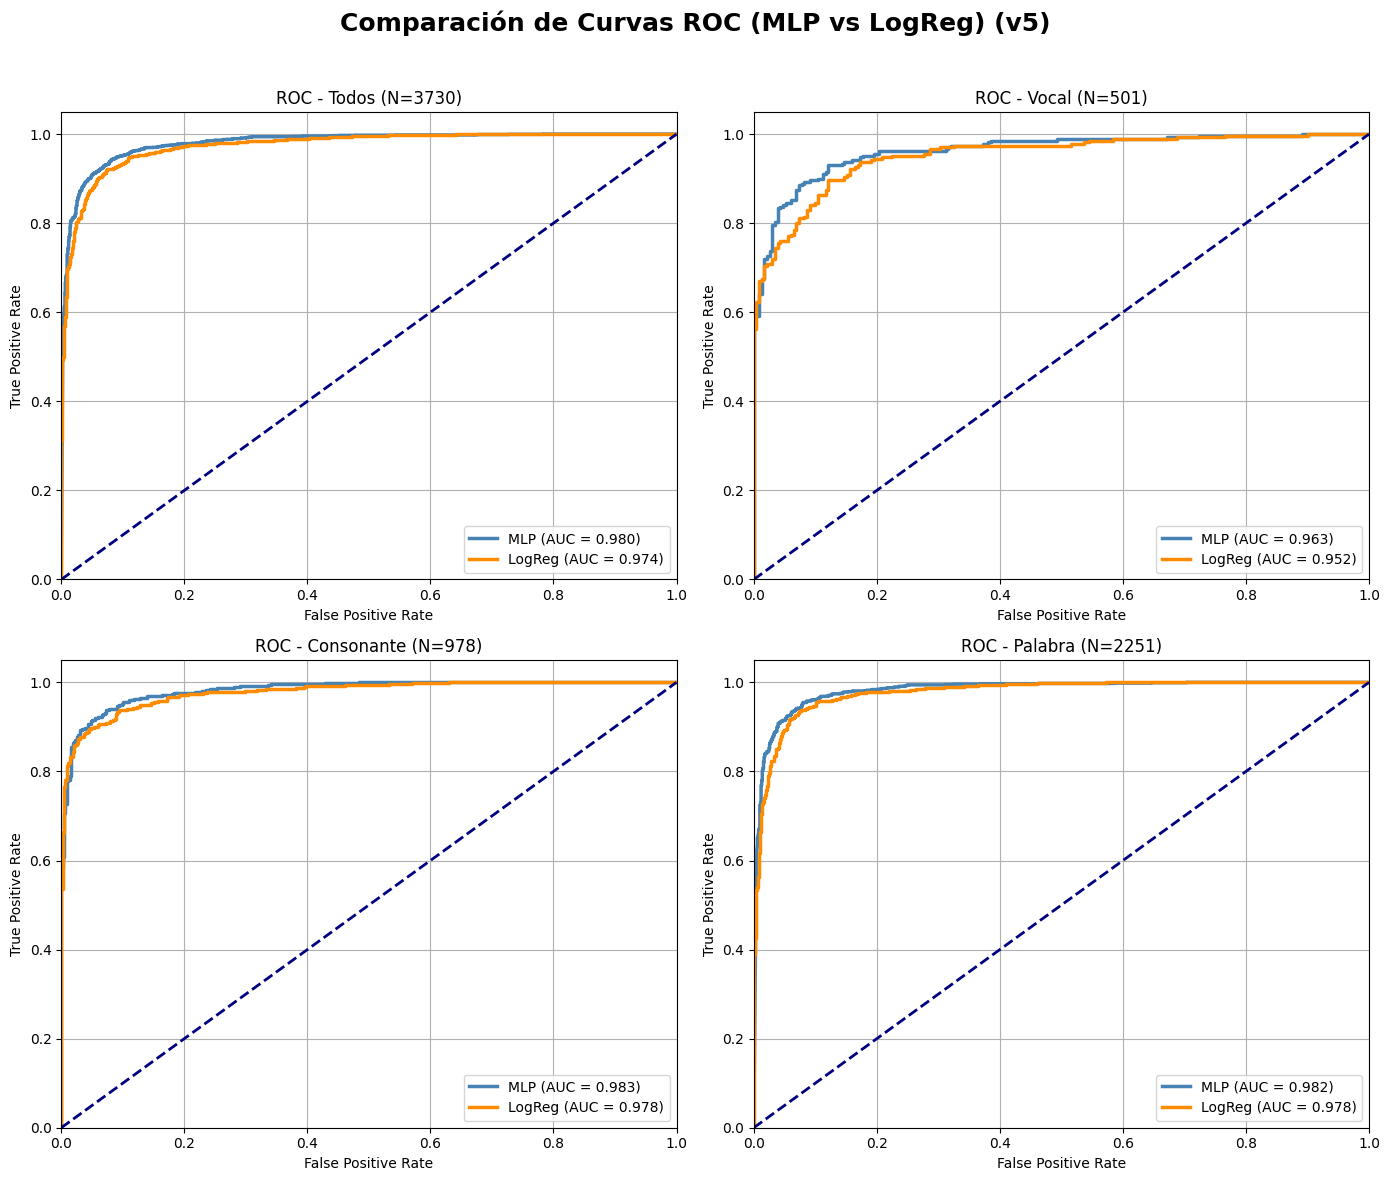

In [13]:
# ===============================================================_
# 6.12 — Comparativa de Curvas ROC (MLP vs LogReg) por Subconjunto
# ===============================================================_
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import roc_curve, auc, confusion_matrix, accuracy_score, recall_score, precision_score, f1_score, roc_auc_score
import itertools

print("🚀 Generando gráficos ROC comparativos (MLP vs LogReg)...")

try:
    # Cargar los datos de predicciones (generados en celdas 6.7 y 6.10)
    df_mlp = pd.read_csv(preds_mlp_csv_path)
    df_lr = pd.read_csv(preds_lr_csv_path)

    # Definir los subconjuntos
    subsets = {
        'todos': (df_mlp, df_lr),
        'vocal': (df_mlp[df_mlp['tipo'] == 'vocal'], df_lr[df_lr['tipo'] == 'vocal']),
        'consonante': (df_mlp[df_mlp['tipo'] == 'consonante'], df_lr[df_lr['tipo'] == 'consonante']),
        'palabra': (df_mlp[df_mlp['tipo'] == 'palabra'], df_lr[df_lr['tipo'] == 'palabra'])
    }

    # Crear la figura 2x2 para las curvas ROC
    fig_roc, axes_roc = plt.subplots(2, 2, figsize=(14, 12))
    fig_roc.suptitle('Comparación de Curvas ROC (MLP vs LogReg) (v5)', fontsize=18, fontweight='bold')

    # Iterar y graficar
    for (ax, (subset_name, (df_m, df_l))) in zip(axes_roc.flat, subsets.items()):
        
        # --- MLP ---
        y_true_mlp = df_m['y_true']
        y_proba_mlp = df_m['proba_patient']
        fpr_mlp, tpr_mlp, _ = roc_curve(y_true_mlp, y_proba_mlp)
        auc_mlp = auc(fpr_mlp, tpr_mlp)
        ax.plot(fpr_mlp, tpr_mlp, color='steelblue', lw=2.5, label=f'MLP (AUC = {auc_mlp:.3f})')

        # --- LogReg ---
        y_true_lr = df_l['y_true']
        y_proba_lr = df_l['proba_patient_logreg']
        fpr_lr, tpr_lr, _ = roc_curve(y_true_lr, y_proba_lr)
        auc_lr = auc(fpr_lr, tpr_lr)
        ax.plot(fpr_lr, tpr_lr, color='darkorange', lw=2.5, label=f'LogReg (AUC = {auc_lr:.3f})')

        # --- Formato ---
        ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
        ax.set_xlim([0.0, 1.0])
        ax.set_ylim([0.0, 1.05])
        ax.set_xlabel('False Positive Rate')
        ax.set_ylabel('True Positive Rate')
        ax.set_title(f'ROC - {subset_name.capitalize()} (N={len(df_m)})')
        ax.legend(loc="lower right")
        ax.grid(True)

    fig_roc.tight_layout(rect=[0, 0, 1, 0.96])
    
    # Guardar figura
    roc_path = ITELConfig.FIGURAS_DIR / 'roc_curves_comparacion_v5.png'
    fig_roc.savefig(roc_path, dpi=300)
    print(f"\n💾 Gráficos ROC comparativos guardados en: {roc_path}")

except FileNotFoundError:
    print(f"⚠️ Error en 6.12: No se encontraron los archivos CSV de predicciones. Asegúrate de ejecutar las celdas 6.7 y 6.10 primero.")
except Exception as e:
    print(f"⚠️ Ocurrió un error al graficar ROC (6.12): {e}")


🚀 Generando Matrices de Confusión comparativas (MLP vs LogReg)...

💾 Gráficos CM comparativos guardados en: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\Figuras\confusion_matrices_comparacion_v5.png


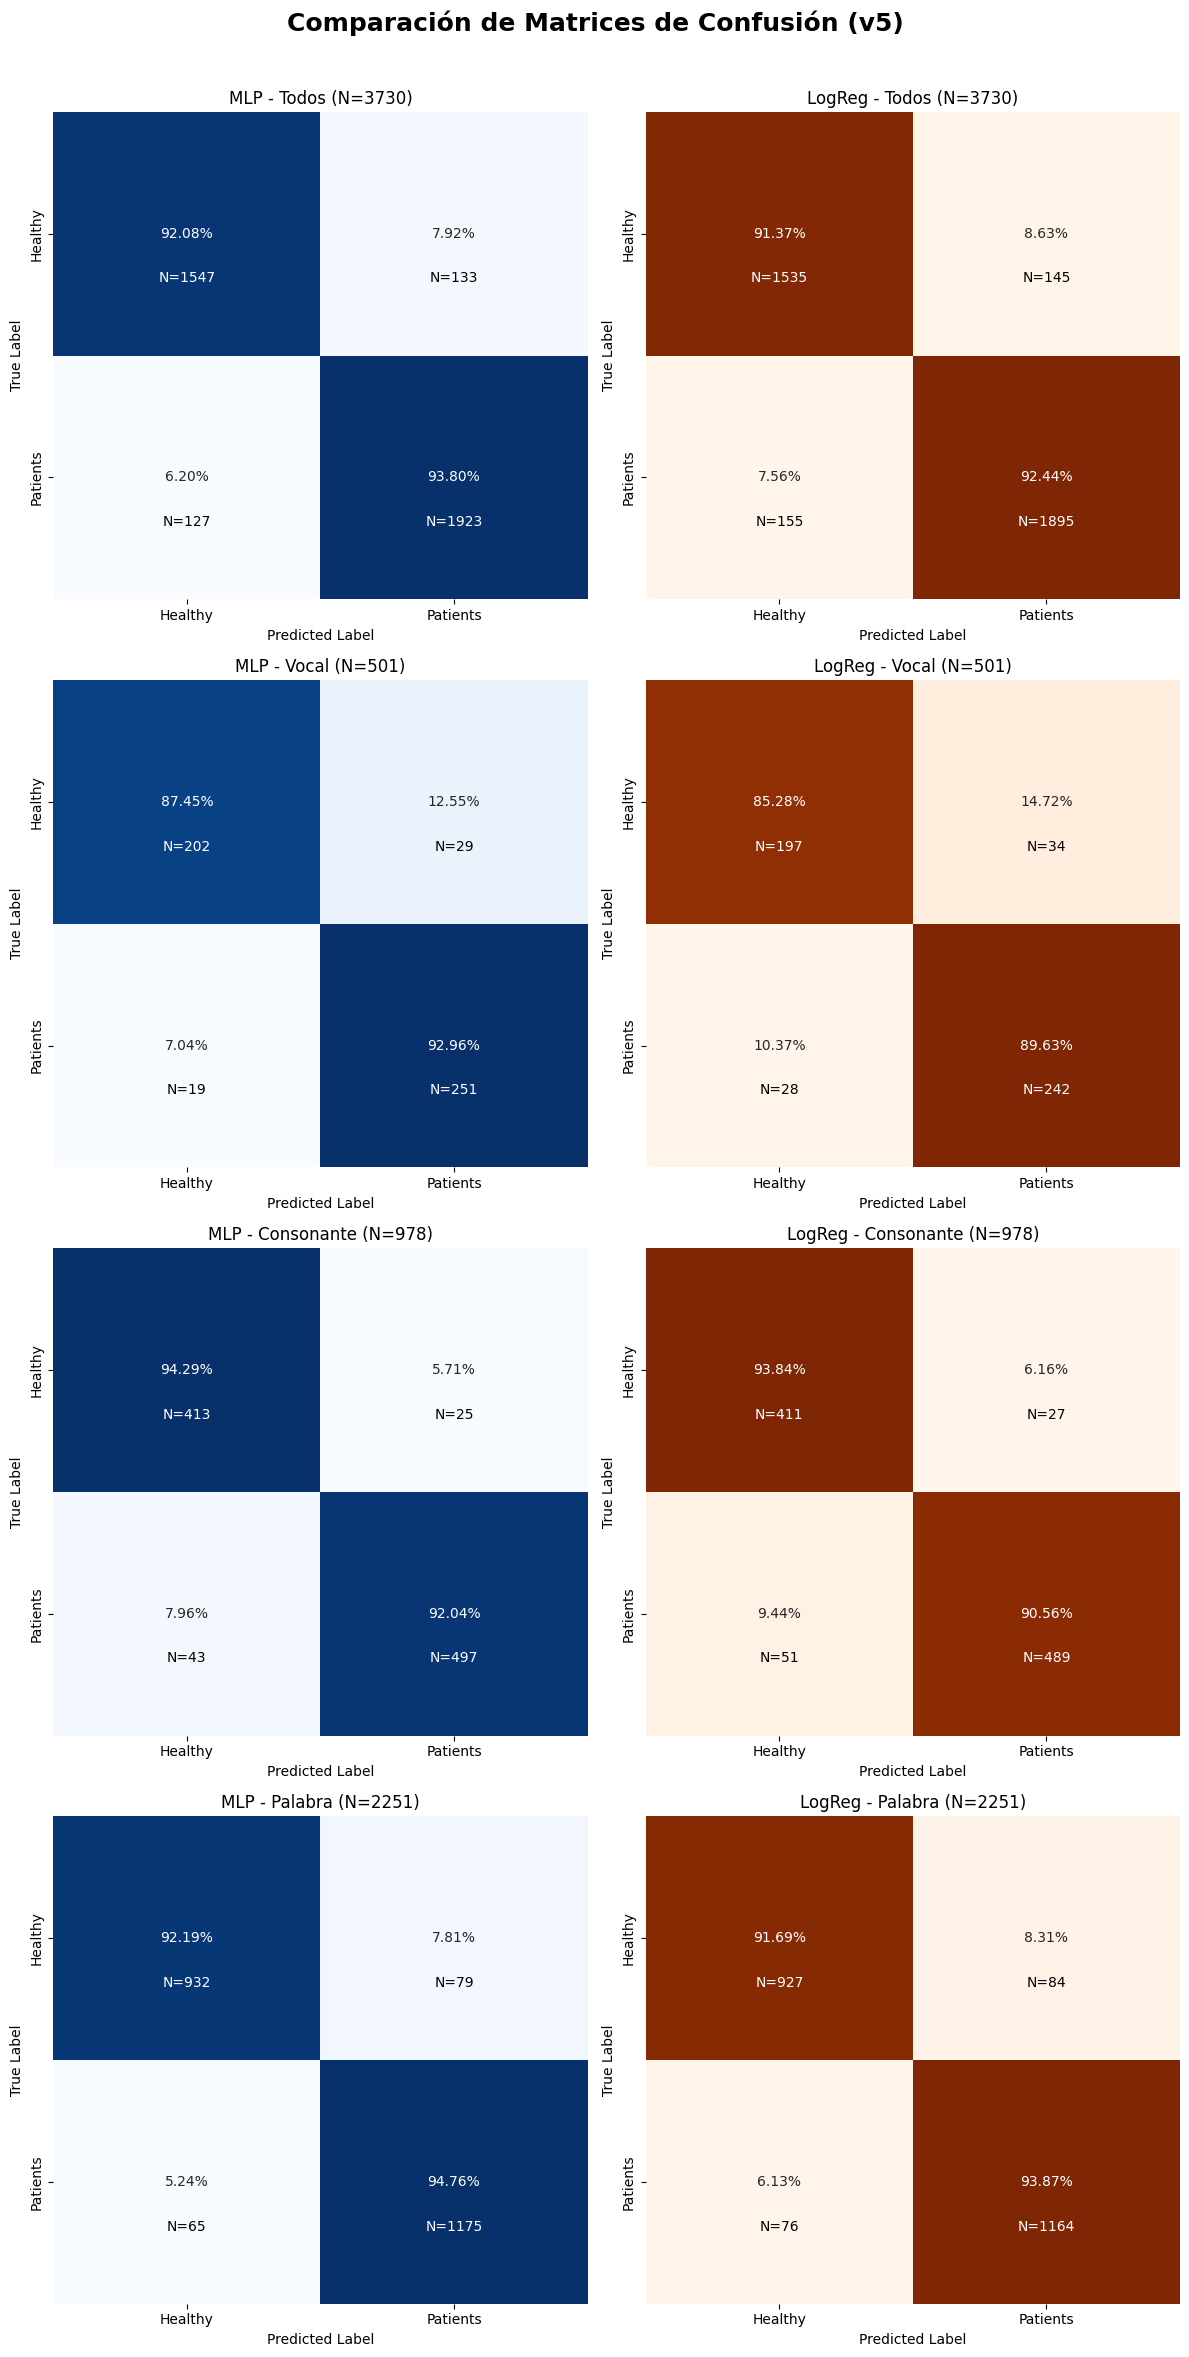

In [14]:
# ===============================================================_
# 6.13 — Comparativa de Matrices de Confusión (MLP vs LogReg)
# ===============================================================_

print("\n🚀 Generando Matrices de Confusión comparativas (MLP vs LogReg)...")

try:
    # Cargar datos (si no están cargados)
    if 'df_mlp' not in locals():
        df_mlp = pd.read_csv(preds_mlp_csv_path)
    if 'df_lr' not in locals():
        df_lr = pd.read_csv(preds_lr_csv_path)

    # Definir los subconjuntos
    subsets_list = ['todos', 'vocal', 'consonante', 'palabra']
    
    # Crear la figura 4x2
    fig_cm, axes_cm = plt.subplots(4, 2, figsize=(12, 24))
    fig_cm.suptitle('Comparación de Matrices de Confusión (v5)', fontsize=18, fontweight='bold')

    for i, subset_name in enumerate(subsets_list):
        
        # --- Preparar datos del subconjunto ---
        if subset_name == 'todos':
            df_m_sub = df_mlp
            df_l_sub = df_lr
        else:
            df_m_sub = df_mlp[df_mlp['tipo'] == subset_name]
            df_l_sub = df_lr[df_lr['tipo'] == subset_name]

        y_true_m = df_m_sub['y_true']
        y_pred_m = df_m_sub['y_pred']
        
        y_true_l = df_l_sub['y_true']
        y_pred_l = df_l_sub['y_pred_logreg']

        # --- 1. Gráfico CM para MLP (Columna 0) ---
        ax_mlp = axes_cm[i, 0]
        cm_mlp = confusion_matrix(y_true_m, y_pred_m)
        cm_mlp_norm = cm_mlp.astype('float') / cm_mlp.sum(axis=1)[:, np.newaxis]
        
        sns.heatmap(cm_mlp_norm, annot=True, fmt='.2%', cmap='Blues', ax=ax_mlp, cbar=False,
                    xticklabels=['Healthy', 'Patients'], yticklabels=['Healthy', 'Patients'])
        
        for r, c in itertools.product(range(cm_mlp.shape[0]), range(cm_mlp.shape[1])):
            ax_mlp.text(c + 0.5, r + 0.7, f"N={cm_mlp[r, c]}",
                       horizontalalignment="center",
                       color="black" if cm_mlp_norm[r, c] < 0.7 else "white")
        
        ax_mlp.set_title(f'MLP - {subset_name.capitalize()} (N={len(y_true_m)})')
        ax_mlp.set_ylabel('True Label')
        ax_mlp.set_xlabel('Predicted Label')

        # --- 2. Gráfico CM para LogReg (Columna 1) ---
        ax_lr = axes_cm[i, 1]
        cm_lr = confusion_matrix(y_true_l, y_pred_l)
        cm_lr_norm = cm_lr.astype('float') / cm_lr.sum(axis=1)[:, np.newaxis]
        
        sns.heatmap(cm_lr_norm, annot=True, fmt='.2%', cmap='Oranges', ax=ax_lr, cbar=False,
                    xticklabels=['Healthy', 'Patients'], yticklabels=['Healthy', 'Patients'])

        for r, c in itertools.product(range(cm_lr.shape[0]), range(cm_lr.shape[1])):
            ax_lr.text(c + 0.5, r + 0.7, f"N={cm_lr[r, c]}",
                       horizontalalignment="center",
                       color="black" if cm_lr_norm[r, c] < 0.7 else "white")

        ax_lr.set_title(f'LogReg - {subset_name.capitalize()} (N={len(y_true_l)})')
        ax_lr.set_ylabel('True Label')
        ax_lr.set_xlabel('Predicted Label')

    fig_cm.tight_layout(rect=[0, 0, 1, 0.97])
    
    # 3. Guardar figura
    cm_path = ITELConfig.FIGURAS_DIR / 'confusion_matrices_comparacion_v5.png'
    fig_cm.savefig(cm_path, dpi=300)
    print(f"\n💾 Gráficos CM comparativos guardados en: {cm_path}")

except FileNotFoundError:
    print(f"⚠️ Error en 6.13: No se encontraron los archivos CSV de predicciones. Asegúrate de ejecutar las celdas 6.7 y 6.10 primero.")
except Exception as e:
    print(f"⚠️ Ocurrió un error al graficar CM (6.13): {e}")


🚀 Generando gráfico comparativo de métricas (Global)...

💾 Gráfico de Comparación de Métricas Globales guardado en: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\Figuras\metricas_comparacion_global_v5.png


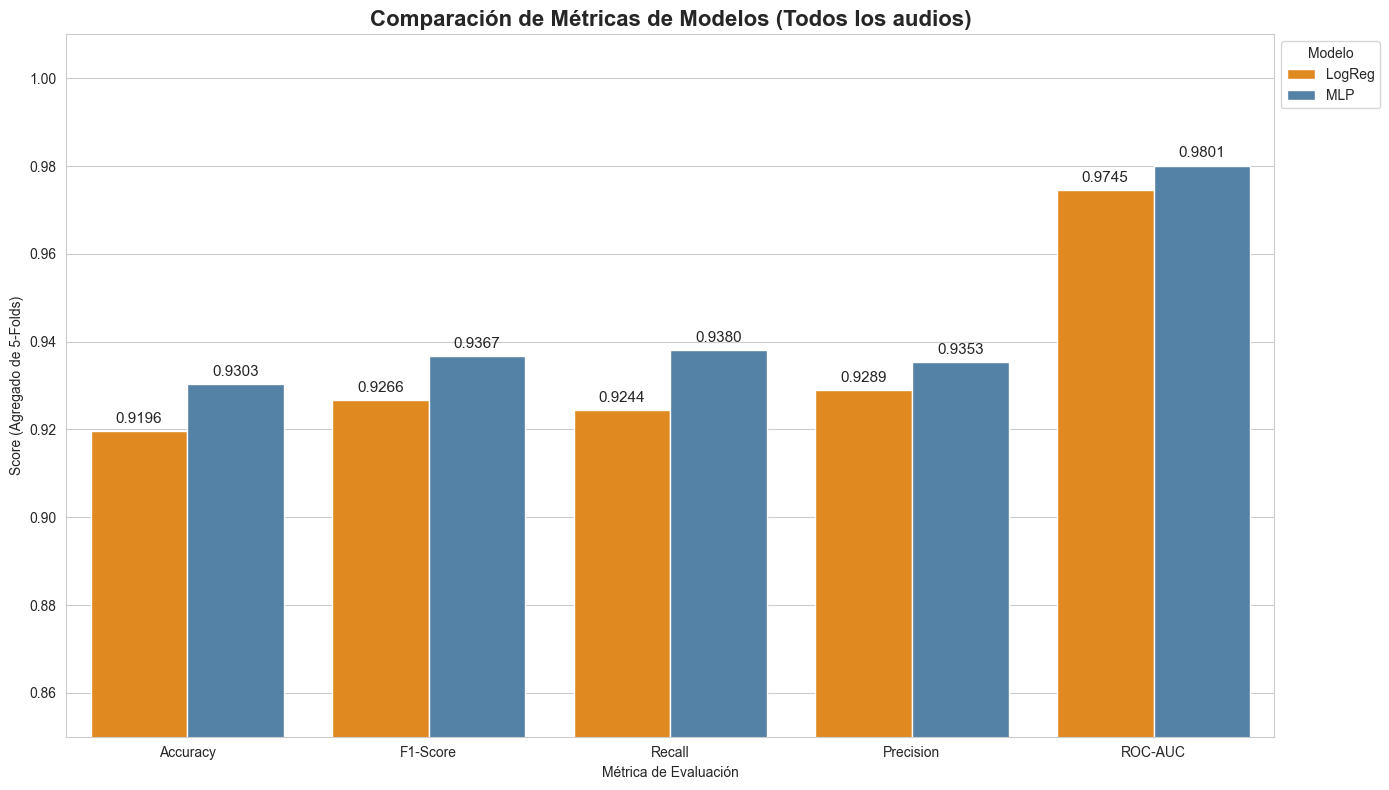

In [15]:
# ===============================================================_
# 6.14 — Gráfico Comparativo de Métricas (Global)
# ===============================================================_

print("\n🚀 Generando gráfico comparativo de métricas (Global)...")

try:
    # Cargar el resumen de HPO/CV (generado en celdas 6.6 y 6.10)
    df_resumen = pd.read_csv(resumen_csv)

    # Re-nombrar modelos para el gráfico
    df_resumen['modelo'] = df_resumen['modelo'].replace({
        'LogReg_sklearn_CV_HPO_f1': 'LogReg',
        'MLP_HuBERT_v5_CV_Subject': 'MLP'
    })

    # Convertir de formato "ancho" a "largo" para seaborn
    df_plot = df_resumen.melt(
        id_vars=['modelo'], 
        var_name='metric', 
        value_name='score'
    )
    
    # --- INICIO DE MODIFICACIÓN ---
    # Limpiar nombres de métricas (Mapeo más robusto)
    df_plot['metric'] = df_plot['metric'].str.replace('test_', '')
    metric_map = {
        'accuracy': 'Accuracy',
        'f1': 'F1-Score',
        'recall': 'Recall',
        'precision': 'Precision',
        'roc_auc': 'ROC-AUC'
    }
    df_plot['metric'] = df_plot['metric'].map(metric_map)
    # --- FIN DE MODIFICACIÓN ---

    # --- Graficar ---
    plt.figure(figsize=(14, 8))
    sns.set_style("whitegrid")
    palette = {'MLP': 'steelblue', 'LogReg': 'darkorange'}

    # Orden actualizado para coincidir con el mapeo
    metric_order = ['Accuracy', 'F1-Score', 'Recall', 'Precision', 'ROC-AUC']
    
    ax_comp = sns.barplot(
        data=df_plot, 
        x='metric', 
        y='score', 
        hue='modelo', 
        palette=palette,
        order=metric_order # Usar el orden definido
    )
    
    ax_comp.set_ylim(0.85, 1.01) # Ajustar zoom en la parte alta
    ax_comp.set_title('Comparación de Métricas de Modelos (Todos los audios)', fontsize=16, fontweight='bold')
    ax_comp.set_ylabel('Score (Agregado de 5-Folds)')
    ax_comp.set_xlabel('Métrica de Evaluación')
    
    # Añadir etiquetas de valor
    for p in ax_comp.patches:
        ax_comp.annotate(f"{p.get_height():.4f}", 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', 
                    xytext=(0, 9), 
                    textcoords='offset points',
                    fontsize=11)
    
    plt.legend(loc='upper left', bbox_to_anchor=(1, 1), title='Modelo')
    plt.tight_layout()

    # Guardar figura
    comp_path = ITELConfig.FIGURAS_DIR / 'metricas_comparacion_global_v5.png'
    plt.savefig(comp_path, dpi=300)
    print(f"\n💾 Gráfico de Comparación de Métricas Globales guardado en: {comp_path}")
    plt.show()

except FileNotFoundError:
    print(f"⚠️ Error en 6.14: No se encontró el archivo {resumen_csv}. Asegúrate de ejecutar las celdas 6.6 y 6.10 primero.")
except Exception as e:
    print(f"⚠️ Ocurrió un error al generar el gráfico comparativo (6.14): {e}")